# Lista 8

Zuzanna Sosnowska

In [1]:
import pandas as pd
import numpy as np

### Zadanie 1

**Wczytanie i eksploracja danych:** Wczytaj publicznie dostępny zbiór danych do analizy wydźwięku (np. zbiór recenzji filmowych z IMDB). Zapoznaj się z danymi: sprawdź liczbę recenzji, rozkład klas, i długość tekstu.

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")

path = path + "/IMDB Dataset.csv"
print("Path to dataset files:", path)

Path to dataset files: /Users/zuzannasosnowska/.cache/kagglehub/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/versions/1/IMDB Dataset.csv


In [3]:
df = pd.read_csv(path)

df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
df.isna().sum()

review       0
sentiment    0
dtype: int64

### Zadanie 2

**Przygotowanie danych tekstowych:** Przeprowadź pre-processing danych tekstowych, który powinien obejmować co najmniej:
- usunięcie znaków interpunkcyjnych i cyfr,
- konwersję tekstu na małe litery,
- usunięcie stopwords (słów-wypełniaczy).

In [5]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


def text_preprocessing(column):
    filtered_text_list = []
    for text in column:
        lemmatizer = WordNetLemmatizer()
        stop_words = set(stopwords.words('english'))
        text = re.sub(r'(\s|[^\w]|_|\d)+', " ", text)  # Zastępowanie znaków specjalnych i cyfr spacją
        text = re.sub(r'^\s|\s$', "", text)  # Usuwanie 'białych znaków' (spacji, tab'ów) z początku i końca tekstu
        text = text.lower()  # Zmiana liter na małe
        filtered_words = text.split(" ")  # Tworzenie listy słów odseparowanych spacją
        filtered_words = [lemmatizer.lemmatize(w) for w in filtered_words if not w in stop_words]
        # Usunięcie stop-wordów i lematyzacja (zamiana słów na podstawową formę)

        filtered_text_list.append(' '.join(filtered_words))
    return filtered_text_list

df['review'] = text_preprocessing(df['review'])

W tym zadaniu stworzyłam funkcję, która zadaną kolumnę z tekstem pre-processuje, tzn. usunie znaki interpunkcyjne i cyfry, przekonwertuje wielkie litery na małe, lematyzuje tekst, tzn. zamieni słowa na podstawową, prostą formę, np. "ludzi" -> "człowiek" oraz usunie słowa-wypełniacze. Operacja ta została przeprowadzona na wcześniej wszytanych danych.

### Zadanie 3

**Wektoryzacja tekstu:** Przekształć dane tekstowe na format numeryczny, który może być użyty przez model uczenia maszynowego. Zastosuj jedną z następujących technik:
- **Bag-of-Words (Bag of words):** Użyj `CountVectorizer` lub `TfidfVectorizer` z `scikit-learn`.
- `wektoryzacja słów (Word Embeddings):` Użyj gotowych wytrenowanych wektorów (np. `GloVe`) lub wytrenuj własne, jeśli czas na to pozwala.

In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

tfidf = TfidfVectorizer(max_features=5000)
X_tfidf = tfidf.fit_transform(df['review'])

countv = CountVectorizer(max_features=5000)
X_countv = countv.fit_transform(df['review'])

In [45]:
print(tfidf.get_feature_names_out())

['aaron' 'abandoned' 'abc' ... 'zero' 'zombie' 'zone']


`TfidfVectorizer` przekształca tekst na wektory liczbowe, gdzie każdemu słowu przypisywana jest waga oparta na jego częstości w dokumencie i rzadkości w całym zbiorze. Dzięki temu model ML może analizować tekst w formie numerycznej.

`CountVectorizer` przekształca tekst na wektory liczbowe, zliczając, ile razy każde słowo występuje w dokumencie. Pozwala to modelowi ML analizować tekst w postaci liczbowej.

### Zadanie 4

`Budowa modelu klasyfikacji:` Wytrenuj klasyfikator na przygotowanych danych. Możesz użyć:
- Klasycznego modelu ML (`LogisticRegression`, `Naive Bayes`) lub,
- Prostej sieci neuronowej z listy 7 (dla wektoryzacji `Bag-of-Words`).

In [53]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split


X = X_tfidf.toarray()
# X = X_countv.toarray()    # Alternatywna wersja dla CountVectorizer
y = df['sentiment'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()

model.fit(X_train, y_train)

model.score(X_test, y_test)

0.8894

In [48]:
from sklearn.naive_bayes import MultinomialNB

naive_bayes_model = MultinomialNB()
naive_bayes_model.fit(X_train, y_train)

model.score(X_test, y_test)

0.8894

### Zadanie 5

**Ocena i interpretacja wyników:** Oceń wydajność wytrenowanego modelu na zbiorze testowym, używając metryk takich jak dokładność, precyzja i czułość. Dodatkowo przeanalizuj macierz pomyłek.

In [21]:
y_pred_test = model.predict(X_test)
y_pred_train = model.predict(X_train)
y_pred_test = np.where(y_pred_test == 'negative', 0, 1)
y_pred_train = np.where(y_pred_train == 'negative', 0, 1)
y_test = np.where(y_test == 'negative', 0, 1)
y_train = np.where(y_train == 'negative', 0, 1)

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


accuracy_test = accuracy_score(y_test, y_pred_test)
precision_test = precision_score(y_test, y_pred_test)
recall_test = recall_score(y_test, y_pred_test)
f1_test = f1_score(y_test, y_pred_test)

accuracy_train = accuracy_score(y_train, y_pred_train)
precision_train = precision_score(y_train, y_pred_train)
recall_train = recall_score(y_train, y_pred_train)
f1_train = f1_score(y_train, y_pred_train)

pd.DataFrame({"Accuracy": [accuracy_train, accuracy_test],
              "Precision": [precision_train, precision_test],
              "Recall": [recall_train, recall_test],
              "F1": [f1_train, f1_test]},
             index=['train', 'test'])

,Accuracy,Precision,Recall,F1
train,0.912225,0.904376,0.921547,0.912881
test,0.889400,0.880441,0.903155,0.891654


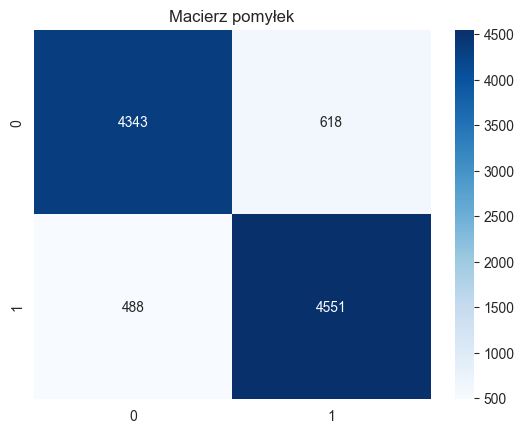

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns


cm = confusion_matrix(y_test, y_pred_test)

sns.heatmap(
    cm,
    annot = True,
    fmt = 'd',
    cmap = 'Blues'
)
plt.title('Macierz pomyłek')
plt.show()

### Zadanie 6

**Predykcja na nowych danych:** Stwórz kilka własnych, krótkich recenzji (jedną pozytywną, jedną negatywną, jedną neutralną). Przetwórz je w taki sam sposób jak dane treningowe i użyj wytrenowanego modelu do predykcji ich wydźwięku. Sprawdź, czy model poprawnie je sklasyfikował.

In [54]:
knives_out_review = "Film follows the investigation into the death of a wealthy crime novelist, whose family gathers after his sudden and mysterious passing. As a private detective begins to uncover the truth, hidden secrets, lies, and family conflicts gradually come to light. The film is brilliantly written and highly entertaining. It draws the viewer in from the very beginning with a clever mystery, sharp dialogue, and excellent pacing. The cast delivers strong performances, and every character feels distinct and purposeful. This is a smart, engaging whodunit that keeps you guessing until the very end and stands out as one of the most enjoyable films in its genre in recent years."

dark_tower_review = "Movie centers on a young boy who discovers a connection between his world and a parallel universe, where a lone gunslinger seeks to protect a mystical tower that holds reality together. Together, they face an evil sorcerer who threatens the balance between worlds. Despite its ambitious premise, the film is a huge disappointment, especially for fans of Stephen King’s novels. It strays far from the source material, oversimplifying the story and flattening the characters. The plot feels rushed and incoherent, and the emotional depth of the books is completely lost. It comes across as a film made without a real understanding of the original work, resulting in a weak and unsatisfying adaptation."

promising_young_lady_review = "History of a young woman who appears to have an unremarkable life but secretly leads a double existence. At night, she puts herself in dangerous situations to confront men who take advantage of women, driven by a traumatic event from her past. The film is bold, unsettling, and deeply engaging. The revenge narrative is told in a fresh and unexpected way, with surprising twists that steadily build tension. The main character is complex and compelling, and the film explores difficult themes without becoming overly moralizing. It is a powerful story that lingers in the viewer’s mind long after the credits roll."

mulan_2020_review = 'New Mulan from 2020 retells the story of a young woman who disguises herself as a man in order to take her father’s place in the army and defend her country from invasion. The film presents this journey in a more serious, live-action format compared to the animated original. Unfortunately, the adaptation is a major disappointment. The movie tries too hard to portray Mulan as an inherently powerful and flawless warrior, which removes the sense of growth and struggle that defined the original character. Instead of relying on intelligence, strategy, and personal development, the film presents a one-dimensional heroine. It lacks humor, emotional depth, and the charm of the animated version, making it feel bland and forgettable.'

snowwhite_2025_review = "The classic fairy tale about a young princess forced to flee from her jealous stepmother and find refuge with a group of companions in the forest. The film attempts to modernize the story for contemporary audiences. However, this adaptation is one of the worst Disney releases in recent years. The main character does not resemble the traditional fairy-tale Snow White, and the dwarfs lack the magical, whimsical quality associated with the story. The film feels unfocused and poorly executed, offering a reinterpretation that fails to capture the charm, nostalgia, or spirit of the original tale."

shrek_review = "Story of a grumpy ogre whose quiet life is disrupted when fairy-tale creatures are exiled to his swamp. In order to get his home back, Shrek sets out on a journey to rescue a princess, accompanied by a talkative donkey. The film is a timeless animated classic with excellent humor and richly developed characters. It works equally well for children and adults, offering jokes on multiple levels and a clever parody of traditional fairy tales. The characters are memorable, the story is engaging, and the message about acceptance and identity is heartfelt. It remains one of the best animated films ever made."

# Opinia neutralna o filmie

harry_potter_review = 'Film introduces the story of a young boy who discovers that he is a wizard and is invited to study at Hogwarts, a magical school hidden from the ordinary world. As Harry learns about magic, friendship, and his past, he also becomes involved in a mystery surrounding a powerful object known as the Philosopher’s Stone. The film is competently made and clearly aimed at a younger audience. The world-building is imaginative, and the visual design successfully brings the magical setting to life. However, for viewers who are not particularly interested in fantasy or the wizarding universe, the story may feel predictable and not especially engaging.'


my_movie_df = pd.DataFrame({
    'review': [
        knives_out_review,
        dark_tower_review,
        promising_young_lady_review,
        mulan_2020_review,
        snowwhite_2025_review,
        shrek_review,
        harry_potter_review
               ],
    'sentiment': [
        'positive',
        'negative',
        'positive',
        'negative',
        'negative',
        'positive',
        'negative'
    ],
})

In [55]:
my_movie_df['review'] = text_preprocessing(my_movie_df['review'])

In [56]:
X_test_tfidf = tfidf.transform(my_movie_df['review'])

In [57]:
y_pred = model.predict(X_test_tfidf)

print(y_pred)

['positive' 'negative' 'positive' 'negative' 'negative' 'positive'
 'positive']


In [58]:
y_test = my_movie_df['sentiment']
y_test = np.where(y_test == 'positive', 1, 0)
y_pred = np.where(y_pred == 'positive', 1, 0)

accuracy_test = accuracy_score(y_test, y_pred)
precision_test = precision_score(y_test, y_pred)
recall_test = recall_score(y_test, y_pred)
f1_test = f1_score(y_test, y_pred)

pd.DataFrame({"Accuracy": [accuracy_test],
              "Precision": [precision_test],
              "Recall": [recall_test],
              "F1": [f1_test]},
             index=['Score dla moich opinii'])

,Accuracy,Precision,Recall,F1
Score dla moich opinii,0.857143,0.75,1.0,0.857143
